# CENG 313 - Assignment 1: Exploratory Data Analysis (EDA) & Baseline Models
**Competition:** [NFL Big Data Bowl 2026 - Prediction](https://www.kaggle.com/competitions/nfl-big-data-bowl-2026-prediction/)  
**Objective:** Predict future $(x, y)$ player coordinates while the pass is in the air using Next Gen Stats tracking data.

In [3]:
!git clone https://github.com/erayakpnr/GROUP64_CENG313.git
%cd GROUP64_CENG313

!mkdir -p ~/.kaggle
!cp /content/kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle competitions download -c nfl-big-data-bowl-2026-prediction -p /content/data
!unzip -q /content/data/nfl-big-data-bowl-2026-prediction.zip -d /content/data/nfl

Cloning into 'GROUP64_CENG313'...
remote: Enumerating objects: 15, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 15 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (15/15), 8.09 KiB | 1.62 MiB/s, done.
/content/GROUP64_CENG313/GROUP64_CENG313
nfl-big-data-bowl-2026-prediction.zip: Skipping, found more recently modified local copy (use --force to force download)
replace /content/data/nfl/kaggle_evaluation/__init__.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/data/nfl/kaggle_evaluation/core/__init__.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/data/nfl/kaggle_evaluation/core/base_gateway.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/data/nfl/kaggle_evaluation/core/generated/__init__.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/data/nfl/kaggle_evaluation/core/generated/kaggle_evaluation_pb2.py? [y]es, [n]o, [A]ll, [N]one, [r]enam

In [4]:
import sys
import pandas as pd
import numpy as np
sys.path.append("./src")

from data import load_week_data, get_dataset_summary, prepare_baseline_features
from utils import plot_kinematic_distributions, plot_position_speeds, plot_play_trajectory
from models import StationaryBaseline, KinematicBaseline, RidgeTrajectoryBaseline, compute_rmse

DATA_DIR = "/content/data/nfl"
# Eğitim için Hafta 1, Doğrulama (Validation) için Hafta 2 verisini yüklüyoruz (RAM dostu)
df_in_w1, df_out_w1 = load_week_data(DATA_DIR, week=1)
df_in_w2, df_out_w2 = load_week_data(DATA_DIR, week=2)

summary = get_dataset_summary(df_in_w1, df_out_w1)
print("=== Week 1 Dataset Summary ===")
for k, v in summary.items():
    print(f"{k}: {v}")

display(df_in_w1.head())

=== Week 1 Dataset Summary ===
input_rows: 285714
output_rows: 32088
unique_games: 16
unique_plays: 819
unique_players: 737
players_to_predict: 563
missing_values_in: 0
missing_values_out: 0


,game_id,play_id,player_to_predict,nfl_id,frame_id,play_direction,absolute_yardline_number,player_name,player_height,player_weight,...,player_role,x,y,s,a,dir,o,num_frames_output,ball_land_x,ball_land_y
0,2023090700,101,False,54527,1,right,42,Bryan Cook,6-1,210,...,Defensive Coverage,52.33,36.94,0.09,0.39,322.40,238.24,21,63.259998,-0.22
1,2023090700,101,False,54527,2,right,42,Bryan Cook,6-1,210,...,Defensive Coverage,52.33,36.94,0.04,0.61,200.89,236.05,21,63.259998,-0.22
2,2023090700,101,False,54527,3,right,42,Bryan Cook,6-1,210,...,Defensive Coverage,52.33,36.93,0.12,0.73,147.55,240.60,21,63.259998,-0.22
3,2023090700,101,False,54527,4,right,42,Bryan Cook,6-1,210,...,Defensive Coverage,52.35,36.92,0.23,0.81,131.40,244.25,21,63.259998,-0.22
4,2023090700,101,False,54527,5,right,42,Bryan Cook,6-1,210,...,Defensive Coverage,52.37,36.90,0.35,0.82,123.26,244.25,21,63.259998,-0.22


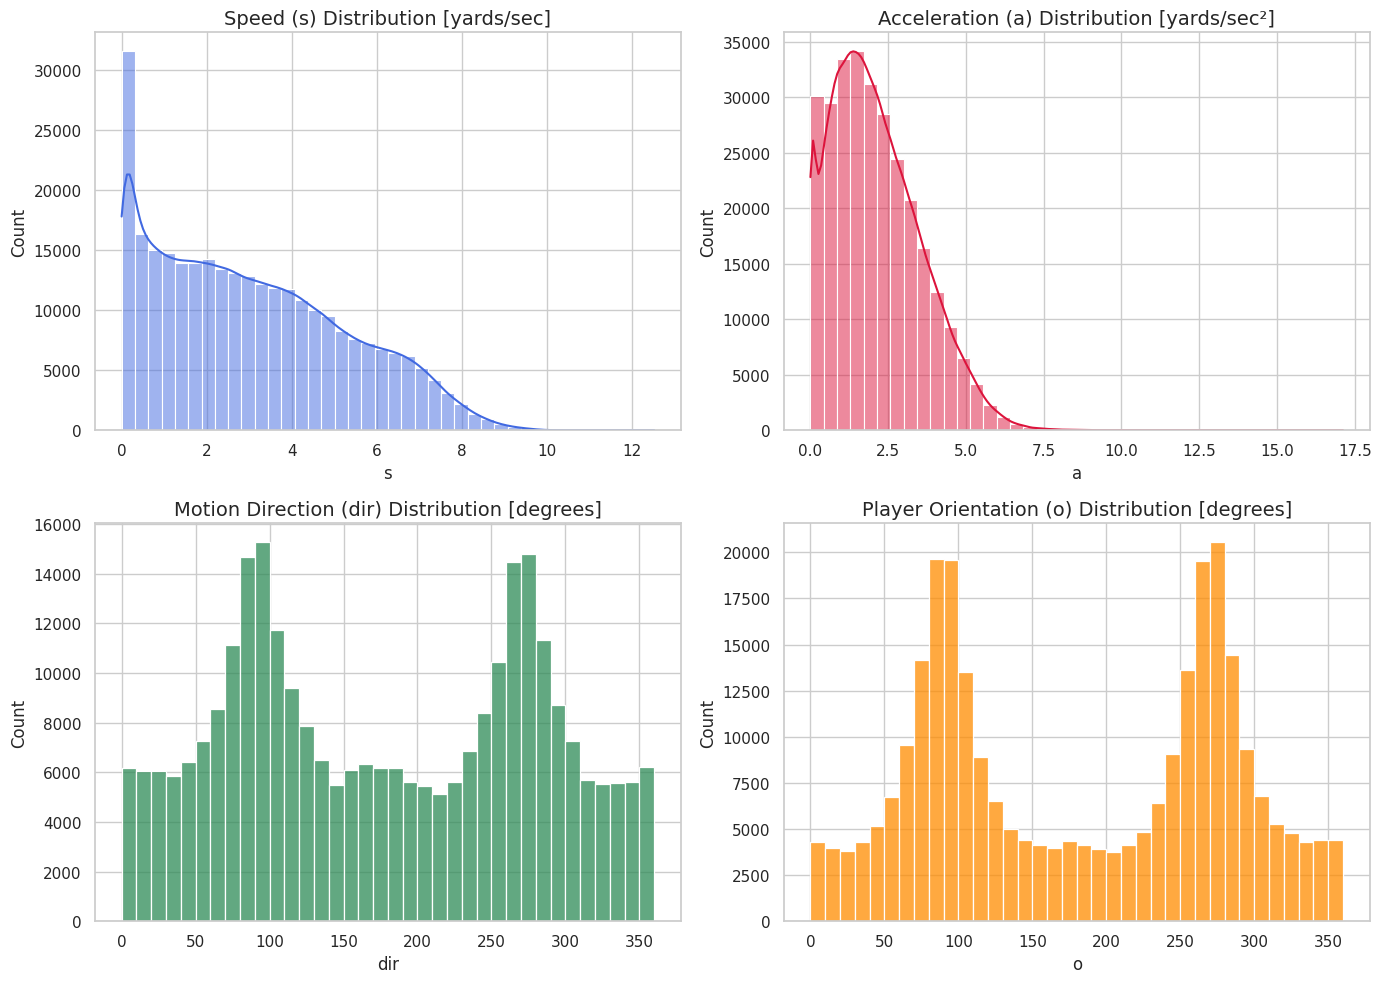

/content/GROUP64_CENG313/GROUP64_CENG313/src/utils.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_in, x="player_position", y="s", order=order, palette="viridis")


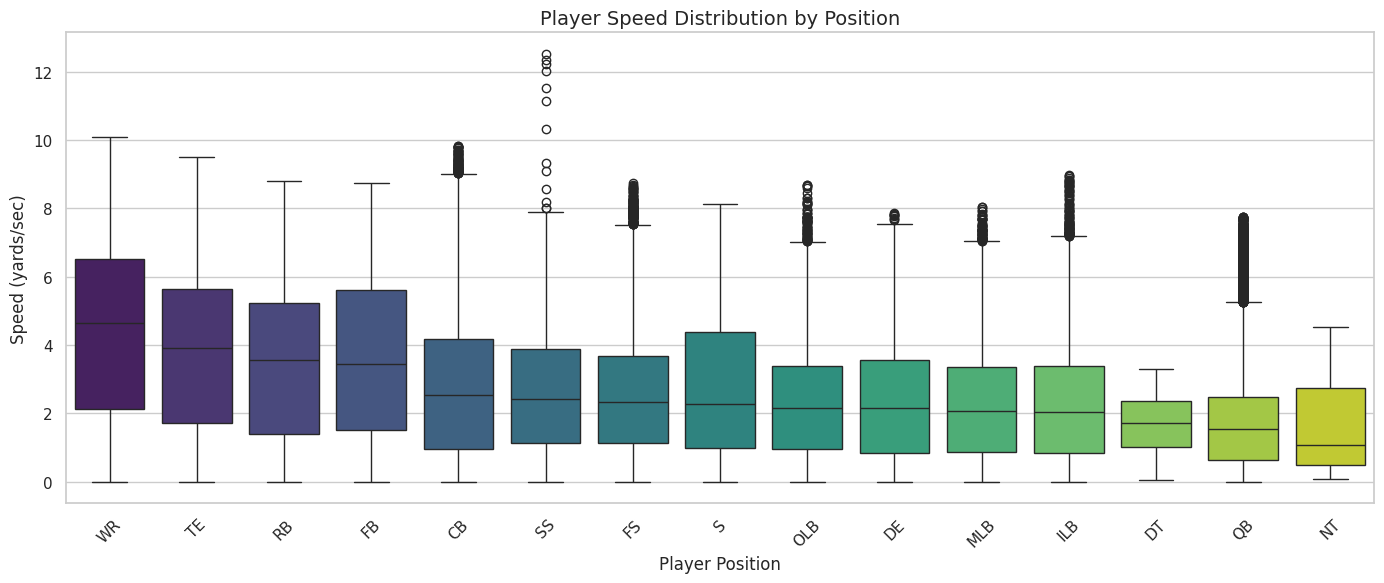

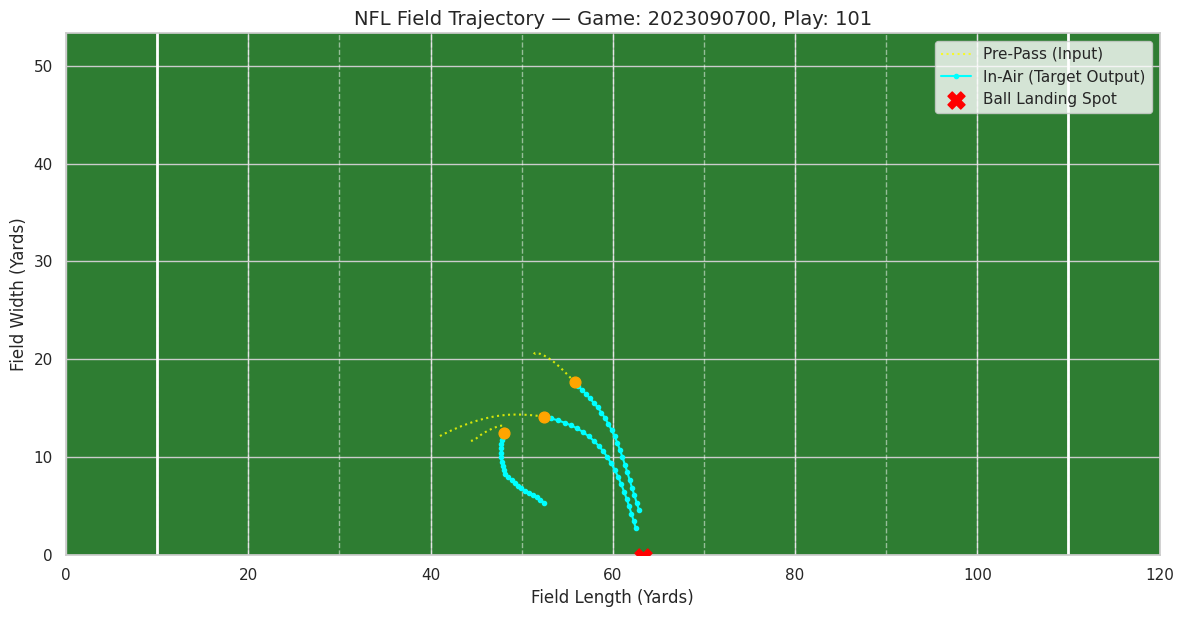

In [5]:
# 1. Hız, İvme, Yön ve Yönelim Dağılımları
plot_kinematic_distributions(df_in_w1)

# 2. Oyuncu Pozisyonlarına Göre Hız Dağılımı
plot_position_speeds(df_in_w1)

# 3. Örnek Bir Oyunun Saha İçi Yörünge Görselleştirmesi
sample_game = df_out_w1["game_id"].iloc[0]
sample_play = df_out_w1["play_id"].iloc[0]
plot_play_trajectory(df_in_w1, df_out_w1, sample_game, sample_play)

In [6]:
# Eğitim (Week 1) ve Validation (Week 2) tablolarını hazırla
train_df = prepare_baseline_features(df_in_w1, df_out_w1)
val_df = prepare_baseline_features(df_in_w2, df_out_w2)

print(f"Train samples: {len(train_df):,} | Validation samples: {len(val_df):,}")

# Baseline 1: Stationary (Sabit Konum)
b1 = StationaryBaseline()
p1_x, p1_y = b1.predict(val_df)
rmse_b1 = compute_rmse(val_df["x"].values, val_df["y"].values, p1_x, p1_y)

# Baseline 2: Physics Kinematic (Sabit Hız + Sönümleme)
b2 = KinematicBaseline(damping=0.85)
p2_x, p2_y = b2.predict(val_df)
rmse_b2 = compute_rmse(val_df["x"].values, val_df["y"].values, p2_x, p2_y)

# Baseline 3: Ridge Regression (Kinematik + Topun Düşüş Noktası Özellikleri)
b3 = RidgeTrajectoryBaseline(alpha=10.0)
b3.fit(train_df)
p3_x, p3_y = b3.predict(val_df)
rmse_b3 = compute_rmse(val_df["x"].values, val_df["y"].values, p3_x, p3_y)

results_df = pd.DataFrame({
    "Baseline Model": [
        "1. Stationary Baseline (Last Frame Hold)",
        "2. Physics Kinematic Baseline (Velocity Extrapolation)",
        "3. Ridge Regression Baseline (Kinematics + Ball Landing)"
    ],
    "Validation RMSE (Yards)": [rmse_b1, rmse_b2, rmse_b3]
})
display(results_df)

Train samples: 32,088 | Validation samples: 32,180


,Baseline Model,Validation RMSE (Yards)
0,1. Stationary Baseline (Last Frame Hold),6.011931
1,2. Physics Kinematic Baseline (Velocity Extrap...,2.338518
2,3. Ridge Regression Baseline (Kinematics + Bal...,2.044564


In [7]:
# Test verisi üzerinden örnek submission dosyasının üretilmesi
test_in = pd.read_csv(f"{DATA_DIR}/test_input.csv")
test_template = pd.read_csv(f"{DATA_DIR}/test.csv")

test_features = prepare_baseline_features(test_in, test_template)
pred_x, pred_y = b3.predict(test_features)

submission = test_template.copy()
submission["x"] = pred_x
submission["y"] = pred_y
submission.to_csv("submission_baseline.csv", index=False)
print("Saved submission_baseline.csv successfully!")
display(submission.head())

Saved submission_baseline.csv successfully!


,id,game_id,play_id,nfl_id,frame_id,x,y
0,12350,2024120805,74,54586,1,87.671596,34.852946
1,12351,2024120805,74,54586,2,87.967275,34.883305
2,12352,2024120805,74,54586,3,88.262954,34.913664
3,12353,2024120805,74,54586,4,88.558632,34.944023
4,12354,2024120805,74,54586,5,88.854311,34.974382
